# Lecture 8 · Logistic Regression, Poisson Regression and GLMs

Following `08_Logistic_Regression.pdf` (Kutner et al., 2005, Ch. 14).

**Data:** `tips.csv`, $n=244$. The earlier weeks modelled a continuous response (the tip). Here the response is binary:

$$Y=1\ \text{if the party smokes (`smoker == Yes`)},\qquad Y=0\ \text{otherwise};\qquad \bar Y=93/244=0.381 .$$

Predictors: `total_bill`, `size`, `sex`, `time` and `day` (3 indicators, baseline Friday). For the count part (L8, slides 27–29) the response is the party `size`.

Smoking status is hard to predict from these variables, and the notebook says so where the numbers show it.

smokers: 93 of 244 (0.381)

share of smokers by group:
  day   Fri: 0.789 (n=19), Sat: 0.483 (n=87), Sun: 0.250 (n=76), Thur: 0.274 (n=62)
  size  1: 0.500 (n=4), 2: 0.423 (n=156), 3: 0.316 (n=38), 4: 0.297 (n=37), 5: 0.400 (n=5), 6: 0.000 (n=4)
  sex   Female: 0.379 (n=87), Male: 0.382 (n=157)
  time  Dinner: 0.398 (n=176), Lunch: 0.338 (n=68)


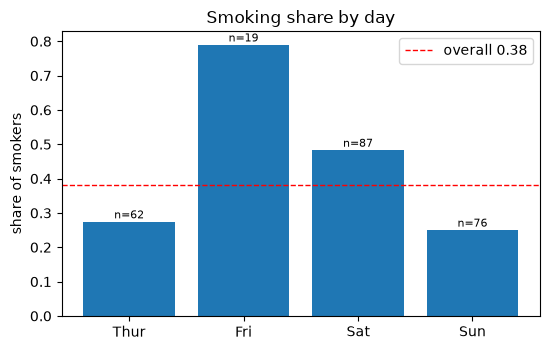

In [1]:
import numpy as np, pandas as pd, itertools, warnings
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

ALPHA = 0.05
df = pd.read_csv('tips.csv')
n = len(df)
y = (df['smoker'] == 'Yes').to_numpy().astype(float)
bill = df['total_bill'].to_numpy()
size_ = df['size'].to_numpy().astype(float)
male = (df['sex'] == 'Male').to_numpy().astype(float)
dinner = (df['time'] == 'Dinner').to_numpy().astype(float)
D_sat, D_sun, D_thu = [(df['day'] == d_).to_numpy().astype(float) for d_ in ['Sat', 'Sun', 'Thur']]   # baseline: Friday
pbar = y.mean()

print(f'smokers: {int(y.sum())} of {n} ({pbar:.3f})\n')
print('share of smokers by group:')
for col in ['day', 'size', 'sex', 'time']:
    g = df.groupby(col)['smoker'].agg(lambda s: (s == 'Yes').mean()).round(3)
    c = df.groupby(col).size()
    print(f'  {col:<5}', ', '.join(f'{k}: {v:.3f} (n={c[k]})' for k, v in g.items()))

order = ['Thur', 'Fri', 'Sat', 'Sun']
rates = [y[df['day'] == d_].mean() for d_ in order]
plt.figure(figsize=(5.6, 3.6))
plt.bar(order, rates)
plt.axhline(pbar, c='r', ls='--', lw=1, label=f'overall {pbar:.2f}')
for i, d_ in enumerate(order): plt.text(i, rates[i] + .01, f'n={(df["day"] == d_).sum()}', ha='center', fontsize=8)
plt.ylabel('share of smokers'); plt.legend(); plt.title('Smoking share by day')
plt.tight_layout()
plt.savefig('images/smoker_by_day.png')
plt.show()

## Why ordinary regression fails (slides 4–5)

$E\{Y\mid X\}=P(Y=1\mid X)=\pi(X)$. A straight line can leave $[0,1]$; $Var\{Y\}=\pi(1-\pi)$ is not constant; the error takes only two values.
The non-constant variance is a property of the model (it exists in theory for every 0/1 response), while whether a test can *detect* it depends on the data: the Breusch–Pagan test below is run on this data set's linear-probability residuals and is not the lecture's claim restated. The first problem appears only when the line reaches an extreme.

In [2]:
Xl = np.column_stack([np.ones(n), bill, size_, D_sat, D_sun, D_thu])
lpm = sm.OLS(y, Xl).fit()
pl = lpm.fittedvalues
print(f'linear probability model: fitted values range from {pl.min():.3f} to {pl.max():.3f};  outside [0,1]: {((pl < 0) | (pl > 1)).sum()} cases')
print(f'implied Var{{Y}} = pi(1-pi) ranges from {(pl*(1-pl)).min():.3f} to {(pl*(1-pl)).max():.3f}  (maximum possible 0.25)')
# the error can take only two values at each x: -pi or 1-pi
e_l = y - pl
print(f'residuals take two values per fitted value: e = -pi_hat (y=0) or 1-pi_hat (y=1); e.g. for pi_hat = {pl[0]:.3f}: {-pl[0]:.3f} or {1-pl[0]:.3f}')
w2 = e_l**2; bw = np.linalg.lstsq(Xl, w2, rcond=None)[0]
chi2 = ((Xl @ bw - w2.mean())**2).sum() / 2 / ((e_l @ e_l) / n)**2
print(f'Breusch-Pagan on the linear-probability residuals: X2 = {chi2:.2f}, df = {Xl.shape[1]-1}, P = {stats.chi2.sf(chi2, Xl.shape[1]-1):.3g}')
print('-> Var{Y} = pi(1-pi) depends on X in theory; in this data the fitted pi stay mid-range, so the dependence is too weak for the test to detect.')

# extremes: where a line would leave the range, an S-curve would not
pis = np.array([.10, .25, .50, .75, .90])
print(f'\n{"pi":>6}{"odds":>8}{"logit":>8}')
for p_ in pis: print(f'{p_:>6.2f}{p_/(1-p_):>8.2f}{np.log(p_/(1-p_)):>8.2f}')

linear probability model: fitted values range from -0.012 to 0.954;  outside [0,1]: 2 cases
implied Var{Y} = pi(1-pi) ranges from -0.012 to 0.250  (maximum possible 0.25)
residuals take two values per fitted value: e = -pi_hat (y=0) or 1-pi_hat (y=1); e.g. for pi_hat = 0.290: -0.290 or 0.710
Breusch-Pagan on the linear-probability residuals: X2 = 4.03, df = 5, P = 0.546
-> Var{Y} = pi(1-pi) depends on X in theory; in this data the fitted pi stay mid-range, so the dependence is too weak for the test to detect.

    pi    odds   logit
  0.10    0.11   -2.20
  0.25    0.33   -1.10
  0.50    1.00    0.00
  0.75    3.00    1.10
  0.90    9.00    2.20


## The logistic model, odds and the odds ratio (slides 6–8)

$$\pi(X)=\frac{e^{\eta}}{1+e^{\eta}},\quad \eta=\beta_0+\beta_1X_1+\dots;\qquad \text{odds}=\frac{\pi}{1-\pi},\quad logit(\pi)=\ln\frac{\pi}{1-\pi}=\eta;\qquad OR_k=e^{\beta_k}.$$

## Estimation by maximum likelihood (slide 14)

No least-squares formula. Newton–Raphson (iteratively reweighted least squares): $\mathbf b\leftarrow\mathbf b+(\mathbf X'\mathbf W\mathbf X)^{-1}\mathbf X'(\mathbf y-\boldsymbol\mu)$,
$\mathbf W=\operatorname{diag}\{\mu_i(1-\mu_i)\}$, and $\widehat{Var}\{\mathbf b\}=(\mathbf X'\mathbf W\mathbf X)^{-1}$. Written by hand below and checked against `statsmodels`.

In [3]:
def loglik(eta, yy): return float((yy * eta - np.logaddexp(0, eta)).sum())

def irls(X, yy, tol=1e-9, maxit=60, log=False):
    b = np.zeros(X.shape[1]); trace = []
    for it in range(1, maxit + 1):
        eta = X @ b; mu = 1 / (1 + np.exp(-eta)); W = mu * (1 - mu)
        H = X.T @ (X * W[:, None])
        step = np.linalg.solve(H, X.T @ (yy - mu))
        b = b + step
        trace.append((it, loglik(X @ b, yy), np.abs(step).max(), b.copy()))
        if np.abs(step).max() < tol: break
    mu = 1 / (1 + np.exp(-(X @ b))); W = mu * (1 - mu)
    cov = np.linalg.inv(X.T @ (X * W[:, None]))
    out = dict(b=b, se=np.sqrt(np.clip(np.diag(cov), 0, None)), cov=cov, ll=loglik(X @ b, yy), mu=mu, W=W, X=X, p=X.shape[1], iters=it, trace=trace)
    return out

ll_null = n * (pbar * np.log(pbar) + (1 - pbar) * np.log(1 - pbar))
print(f'intercept-only model: ln L = {ll_null:.3f}  (= n[pbar ln pbar + (1-pbar) ln(1-pbar)])\n')

# simple logistic regression of smoker on party size
X_s = np.column_stack([np.ones(n), size_])
m_s = irls(X_s, y)
print('Newton-Raphson iterations (smoker ~ size):')
print(f'{"iter":>5}{"ln L":>12}{"max |step|":>13}')
for it, ll_, st, _ in m_s['trace']: print(f'{it:>5}{ll_:>12.5f}{st:>13.2e}')
fit_chk = sm.Logit(y, X_s).fit(disp=0)
assert np.allclose(m_s['b'], fit_chk.params, atol=1e-6) and np.allclose(m_s['se'], fit_chk.bse, atol=1e-6), 'statsmodels disagrees'
b1, s1 = m_s['b'][1], m_s['se'][1]
z1 = b1 / s1
G2 = -2 * (ll_null - m_s['ll'])
print(f'\nlogit(pi) = {m_s["b"][0]:.4f} + ({b1:.4f}) size,   s{{b1}} = {s1:.4f}')
print(f'odds ratio per extra person = exp(b1) = {np.exp(b1):.3f}, 95% CI ({np.exp(b1 - 1.96*s1):.3f}, {np.exp(b1 + 1.96*s1):.3f})')
print(f'Wald z* = {z1:.3f}, P = {2*stats.norm.sf(abs(z1)):.4f};   likelihood ratio G2 = {G2:.3f} on 1 df, P = {stats.chi2.sf(G2, 1):.4f}')
print(f'McFadden R2 = {1 - m_s["ll"]/ll_null:.4f}')
print('\nfitted probability by party size:')
for s_ in [1, 2, 3, 4, 5, 6]:
    pi_ = 1 / (1 + np.exp(-(m_s['b'][0] + b1 * s_)))
    print(f'  size {s_}:  pi = {pi_:.3f}   odds = {pi_/(1-pi_):.3f}   (observed share {y[size_ == s_].mean():.3f}, n = {(size_ == s_).sum()})')

intercept-only model: ln L = -162.168  (= n[pbar ln pbar + (1-pbar) ln(1-pbar)])

Newton-Raphson iterations (smoker ~ size):
 iter        ln L   max |step|
    1  -159.94445     2.73e-01
    2  -159.89983     7.90e-02
    3  -159.89981     1.94e-03
    4  -159.89981     1.01e-06
    5  -159.89981     2.67e-13

logit(pi) = 0.3060 + (-0.3126) size,   s{b1} = 0.1524
odds ratio per extra person = exp(b1) = 0.732, 95% CI (0.543, 0.986)
Wald z* = -2.051, P = 0.0403;   likelihood ratio G2 = 4.536 on 1 df, P = 0.0332
McFadden R2 = 0.0140

fitted probability by party size:
  size 1:  pi = 0.498   odds = 0.993   (observed share 0.500, n = 4)
  size 2:  pi = 0.421   odds = 0.727   (observed share 0.423, n = 156)
  size 3:  pi = 0.347   odds = 0.532   (observed share 0.316, n = 38)
  size 4:  pi = 0.280   odds = 0.389   (observed share 0.297, n = 37)
  size 5:  pi = 0.222   odds = 0.285   (observed share 0.400, n = 5)
  size 6:  pi = 0.172   odds = 0.208   (observed share 0.000, n = 4)


## Multiple logistic regression (slide 17)

$$logit(\pi)=\beta_0+\beta_1\,bill+\beta_2\,size+\beta_3\,Sat+\beta_4\,Sun+\beta_5\,Thur\qquad(\text{Friday is the baseline}).$$

Each $e^{\beta_k}$ is an **adjusted** odds ratio. Wald: $z^*=b_k/s\{b_k\}$, interval $\exp(b_k\pm1.96\,s\{b_k\})$. Likelihood-ratio test for a group of terms:
$G^2=-2(\ln L_R-\ln L_F)\sim\chi^2$ with df = number of extra parameters (slide 15).

In [4]:
terms = {'bill': [bill], 'size': [size_], 'male': [male], 'dinner': [dinner], 'day': [D_sat, D_sun, D_thu]}
tnames = {'bill': ['bill'], 'size': ['size'], 'male': ['male'], 'dinner': ['dinner'], 'day': ['Sat', 'Sun', 'Thur']}
def design(ts): return np.column_stack([np.ones(n)] + [c for t_ in ts for c in terms[t_]])
def names_of(ts): return ['intercept'] + [nm for t_ in ts for nm in tnames[t_]]

ts_M = ['bill', 'size', 'day']
M3 = irls(design(ts_M), y)
nm = names_of(ts_M)
fit3 = sm.Logit(y, design(ts_M)).fit(disp=0)
assert np.allclose(M3['b'], fit3.params, atol=1e-6) and np.allclose(M3['se'], fit3.bse, atol=1e-6) and np.isclose(M3['ll'], fit3.llf)
print(f'converged in {M3["iters"]} iterations;  ln L = {M3["ll"]:.3f}  (null {ll_null:.3f})')
print(f'{"":<12}{"b":>9}{"s{b}":>9}{"z*":>8}{"P":>10}{"OR":>8}{"95% CI for OR":>20}')
for k_, nm_ in enumerate(nm):
    b_, s_ = M3['b'][k_], M3['se'][k_]; z_ = b_ / s_
    ci = f'({np.exp(b_ - 1.96*s_):.3f}, {np.exp(b_ + 1.96*s_):.3f})' if k_ else ''
    print(f'{nm_:<12}{b_:>9.4f}{s_:>9.4f}{z_:>8.2f}{2*stats.norm.sf(abs(z_)):>10.4f}{(np.exp(b_) if k_ else np.nan):>8.3f}{ci:>20}')

# likelihood-ratio tests: drop one term (or the whole day group) at a time
print(f'\n{"drop":<10}{"G2":>8}{"df":>4}{"P":>10}')
for t_ in ts_M:
    red = irls(design([x for x in ts_M if x != t_]), y)
    G = -2 * (red['ll'] - M3['ll']); dfree = len(terms[t_])
    print(f'{t_:<10}{G:>8.3f}{dfree:>4}{stats.chi2.sf(G, dfree):>10.4g}')
G_all = -2 * (ll_null - M3['ll'])
print(f'\nwhole model vs intercept only: G2 = {G_all:.3f} on {M3["p"]-1} df, P = {stats.chi2.sf(G_all, M3["p"]-1):.3g}')
print(f'McFadden R2 = 1 - lnL_full/lnL_null = {1 - M3["ll"]/ll_null:.4f}   (slide 20: 0.2-0.4 is a good fit)')

converged in 6 iterations;  ln L = -143.369  (null -162.168)
                    b     s{b}      z*         P      OR       95% CI for OR
intercept      1.5434   0.6752    2.29    0.0223     nan                    
bill           0.0621   0.0205    3.03    0.0024   1.064      (1.022, 1.108)
size          -0.5904   0.2114   -2.79    0.0052   0.554      (0.366, 0.839)
Sat           -1.3960   0.6151   -2.27    0.0232   0.248      (0.074, 0.827)
Sun           -2.3596   0.6416   -3.68    0.0002   0.094      (0.027, 0.332)
Thur          -2.2104   0.6397   -3.46    0.0005   0.110      (0.031, 0.384)

drop            G2  df         P
bill         9.702   1  0.001841
size         8.775   1  0.003053
day         22.162   3 6.036e-05

whole model vs intercept only: G2 = 37.597 on 5 df, P = 4.55e-07
McFadden R2 = 1 - lnL_full/lnL_null = 0.1159   (slide 20: 0.2-0.4 is a good fit)


## Model selection (slide 18)

The Chapter 9 ideas on the likelihood: $AIC_p=-2\ln L+2p$, $SBC_p=-2\ln L+p\ln n$ (smaller is better; only differences matter). All $2^5=32$ subsets of the five terms
(`day` enters as one group of 3 indicators).

In [5]:
tn = list(terms)
rows = []
for r_ in range(len(tn) + 1):
    for sub in itertools.combinations(tn, r_):
        if sub: m_ = irls(design(sub), y); ll_, p_ = m_['ll'], m_['p']
        else: ll_, p_ = ll_null, 1
        rows.append((sub, p_, ll_, -2 * ll_ + 2 * p_, -2 * ll_ + p_ * np.log(n)))
sel = pd.DataFrame(rows, columns=['sub', 'p', 'll', 'AIC', 'SBC'])
sel['label'] = sel['sub'].apply(lambda s: '+'.join(s) if s else '(intercept only)')
# check AIC against statsmodels for one model
assert np.isclose(sm.Logit(y, design(('bill', 'size', 'day'))).fit(disp=0).aic, sel.loc[sel['label'] == 'bill+size+day', 'AIC'].iloc[0])
print(f'{"model":<30}{"p":>3}{"ln L":>10}{"AIC":>9}{"dAIC":>7}{"SBC":>9}{"dSBC":>7}')
for _, r_ in sel.sort_values('AIC').head(6).iterrows():
    print(f'{r_["label"]:<30}{r_["p"]:>3}{r_["ll"]:>10.2f}{r_["AIC"]:>9.2f}{r_["AIC"] - sel["AIC"].min():>7.2f}{r_["SBC"]:>9.2f}{r_["SBC"] - sel["SBC"].min():>7.2f}')
print(f'\nminimum AIC: {sel.loc[sel["AIC"].idxmin(), "label"]};   minimum SBC: {sel.loc[sel["SBC"].idxmin(), "label"]}')

model                           p      ln L      AIC   dAIC      SBC   dSBC
bill+size+day                   6   -143.37   298.74   0.00   319.72   0.00
bill+size+dinner+day            7   -142.78   299.56   0.82   324.04   4.32
bill+size+male+day              7   -143.36   300.73   1.99   325.21   5.49
bill+size+male+dinner+day       8   -142.77   301.55   2.81   329.53   9.81
bill+day                        5   -147.76   305.51   6.78   323.00   3.28
day                             4   -149.19   306.37   7.63   320.36   0.64

minimum AIC: bill+size+day;   minimum SBC: bill+size+day


## Goodness of fit (slides 19–20)

The deviance $D=-2\ln L$ of ungrouped 0/1 data is **not** a $\chi^2$ lack-of-fit statistic (slide 19: "works best with replicated data"); only differences of deviances are used. For fit, group the cases
in 10 groups of predicted probability and compare observed with expected events (**Hosmer–Lemeshow**; the slide fixes deciles but gives no degrees of freedom, so the standard $\chi^2$ with $g-2$ df is used); McFadden's $R^2$ for a rough analogue of $R^2$.

In [6]:
def hosmer_lemeshow(mu, yy, g=10):
    idx = np.array_split(np.argsort(mu), g)
    chi, rows_ = 0.0, []
    for gi in idx:
        o1, e1, ng = yy[gi].sum(), mu[gi].sum(), len(gi)
        chi += (o1 - e1)**2 / (e1 * (1 - e1 / ng)); rows_.append((ng, mu[gi].mean(), o1, e1))
    return chi, g - 2, rows_

chi_hl, df_hl, hl_rows = hosmer_lemeshow(M3['mu'], y)
print(f'{"group":>6}{"n":>5}{"mean pi_hat":>13}{"observed":>10}{"expected":>10}')
for i, (ng, mp, o1, e1) in enumerate(hl_rows, 1): print(f'{i:>6}{ng:>5}{mp:>13.3f}{o1:>10.0f}{e1:>10.2f}')
print(f'\nHosmer-Lemeshow: X2 = {chi_hl:.3f} on {df_hl} df, P = {stats.chi2.sf(chi_hl, df_hl):.3f}  (a large P means no evidence of lack of fit)')
print(f'deviance D = -2 lnL = {-2*M3["ll"]:.2f} on {n - M3["p"]} df -- not interpreted as a chi-square test (ungrouped data)')
print(f'McFadden R2 = {1 - M3["ll"]/ll_null:.4f}')

 group    n  mean pi_hat  observed  expected
     1   25        0.140         4      3.51
     2   25        0.207         5      5.18
     3   25        0.244         4      6.11
     4   25        0.268         8      6.71
     5   24        0.308         7      7.40
     6   24        0.367         6      8.81
     7   24        0.432        14     10.36
     8   24        0.505        13     12.11
     9   24        0.589        14     14.14
    10   24        0.778        18     18.68

Hosmer-Lemeshow: X2 = 5.343 on 8 df, P = 0.720  (a large P means no evidence of lack of fit)
deviance D = -2 lnL = 286.74 on 238 df -- not interpreted as a chi-square test (ungrouped data)
McFadden R2 = 0.1159


## Diagnostics (slide 21)

Pearson residual $r_{P,i}=\dfrac{y_i-\hat\pi_i}{\sqrt{\hat\pi_i(1-\hat\pi_i)}}$, deviance residual $d_i=\pm\sqrt{-2[y_i\ln\hat\pi_i+(1-y_i)\ln(1-\hat\pi_i)]}$,
leverage $h_{ii}$ from the weighted fit ($\mathbf H=\mathbf W^{1/2}\mathbf X(\mathbf X'\mathbf W\mathbf X)^{-1}\mathbf X'\mathbf W^{1/2}$), and for influence the **exact** change when case $i$ is deleted:
$\Delta D_i$ (change in deviance) and a Cook-type distance $(\mathbf b-\mathbf b_{(i)})'\mathbf X'\mathbf W\mathbf X(\mathbf b-\mathbf b_{(i)})/p$. The slides name these measures without formulas, so these are the textbook definitions, not the lecture's.

sum of squared Pearson residuals = 244.56,  sum of squared deviance residuals = 286.74 (= deviance 286.74)
leverage: mean 0.0246 (= p/n = 0.0246), max 0.0796, cases above 2p/n = 0.0492: 24
one-step Cook approximation vs exact deletion: correlation 0.997

  row   bill size  day  y  pi_hat    r_P      d    h_ii   dDev    Cook
   94  22.75    2  Fri  0   0.855  -2.43  -1.97  0.0432   4.14  0.0553
   91  22.49    2  Fri  0   0.853  -2.41  -1.96  0.0435   4.11  0.0548
   99  12.46    2  Fri  0   0.757  -1.76  -1.68  0.0602   3.04  0.0415
  223  15.98    3  Fri  0   0.682  -1.47  -1.51  0.0778   2.48  0.0373
  187  30.46    5  Sun  1   0.133   2.56   2.01  0.0277   4.23  0.0346
  216  28.15    5  Sat  1   0.258   1.70   1.65  0.0488   2.86  0.0273

largest |Pearson residual| = 2.56; largest |deviance residual| = 2.01;  largest Cook-type distance = 0.055


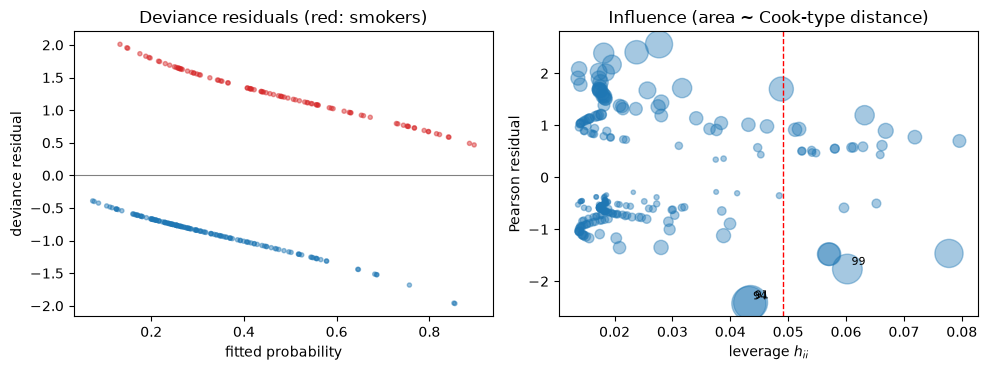

In [7]:
Xm, mu, W = M3['X'], M3['mu'], M3['W']
rP = (y - mu) / np.sqrt(mu * (1 - mu))
dres = np.sign(y - mu) * np.sqrt(-2 * (y * np.log(mu) + (1 - y) * np.log(1 - mu)))
Wh = np.sqrt(W)[:, None] * Xm
hlev = np.einsum('ij,jk,ik->i', Wh, np.linalg.inv(Wh.T @ Wh), Wh)

glm = sm.GLM(y, Xm, family=sm.families.Binomial()).fit()
infl = glm.get_influence()
assert np.allclose(hlev, infl.hat_matrix_diag, atol=1e-8), 'leverage differs from statsmodels'
assert np.allclose(rP, glm.resid_pearson, atol=1e-8) and np.allclose(dres, glm.resid_deviance, atol=1e-8)
print(f'sum of squared Pearson residuals = {(rP**2).sum():.2f},  sum of squared deviance residuals = {(dres**2).sum():.2f} (= deviance {-2*M3["ll"]:.2f})')
print(f'leverage: mean {hlev.mean():.4f} (= p/n = {M3["p"]/n:.4f}), max {hlev.max():.4f}, cases above 2p/n = {2*M3["p"]/n:.4f}: {(hlev > 2*M3["p"]/n).sum()}')

# exact case deletion
dev_all = -2 * M3['ll']
dD = np.empty(n); cook = np.empty(n)
for i in range(n):
    keep = np.arange(n) != i
    mi = irls(Xm[keep], y[keep])
    dD[i] = dev_all - (-2 * mi['ll'])
    db = M3['b'] - mi['b']
    cook[i] = db @ (Xm.T @ (Xm * W[:, None])) @ db / M3['p']
cook1 = rP**2 * hlev / (M3['p'] * (1 - hlev)**2)                 # one-step (textbook) approximation
print(f'one-step Cook approximation vs exact deletion: correlation {np.corrcoef(cook, cook1)[0, 1]:.3f}')

top = np.argsort(-cook)[:6]
print(f'\n{"row":>5}{"bill":>7}{"size":>5}{"day":>5}{"y":>3}{"pi_hat":>8}{"r_P":>7}{"d":>7}{"h_ii":>8}{"dDev":>7}{"Cook":>8}')
for i in top:
    print(f'{i:>5}{bill[i]:>7.2f}{size_[i]:>5.0f}{df["day"][i]:>5}{y[i]:>3.0f}{mu[i]:>8.3f}{rP[i]:>7.2f}{dres[i]:>7.2f}{hlev[i]:>8.4f}{dD[i]:>7.2f}{cook[i]:>8.4f}')
print(f'\nlargest |Pearson residual| = {np.abs(rP).max():.2f}; largest |deviance residual| = {np.abs(dres).max():.2f};  largest Cook-type distance = {cook.max():.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(mu, dres, s=9, alpha=.45, c=np.where(y == 1, 'C3', 'C0'))
ax[0].axhline(0, c='gray', lw=.8); ax[0].set_xlabel('fitted probability'); ax[0].set_ylabel('deviance residual'); ax[0].set_title('Deviance residuals (red: smokers)')
ax[1].scatter(hlev, rP, s=600 * cook / cook.max() + 6, alpha=.4)
ax[1].axvline(2 * M3['p'] / n, c='r', ls='--', lw=1)
for i in top[:3]: ax[1].annotate(str(i), (hlev[i], rP[i]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[1].set_xlabel('leverage $h_{ii}$'); ax[1].set_ylabel('Pearson residual'); ax[1].set_title("Influence (area ~ Cook-type distance)")
plt.tight_layout()
plt.savefig('images/logit_diagnostics.png')
plt.show()

## Prediction and classification (slides 22–23)

Classify as 1 if $\hat\pi>$ cutoff. Sensitivity $=TP/(TP+FN)$, specificity $=TN/(TN+FP)$, precision $=TP/(TP+FP)$, accuracy $=(TP+TN)/n$. The ROC curve plots sensitivity against
$1-$specificity over all cutoffs; AUC is the area under it ($0.5$ = chance). AUC is also the probability that a random smoker gets a higher $\hat\pi$ than a random non-smoker.

AUC = 0.7209  (trapezoid = rank formula)
Youden-optimal cutoff: 0.407 (sensitivity 0.634, specificity 0.755)

        cutoff   TP   FP   FN   TN  sensit.  specif.  precis.  accur.
          0.50   39   22   54  129    0.419    0.854    0.639   0.689
0.381 (base rate)   59   43   34  108    0.634    0.715    0.578   0.684
0.407 (Youden)   59   37   34  114    0.634    0.755    0.615   0.709

accuracy of the rule "nobody smokes": 0.619


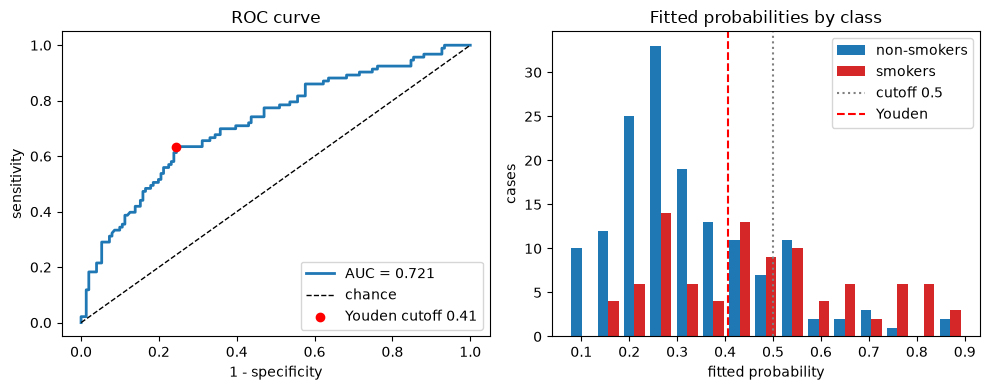

In [8]:
def auc_rank(score, yy):
    r = stats.rankdata(score); n1 = yy.sum(); n0 = len(yy) - n1
    return (r[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def roc_points(score, yy):
    th = np.concatenate([[np.inf], np.sort(np.unique(score))[::-1]])
    tpr = np.array([(score[yy == 1] >= t_).mean() for t_ in th]); fpr = np.array([(score[yy == 0] >= t_).mean() for t_ in th])
    return th, fpr, tpr

th, fpr, tpr = roc_points(mu, y)
auc_trap = np.trapezoid(tpr, fpr)
assert np.isclose(auc_trap, auc_rank(mu, y)), 'ROC area differs from the rank (Mann-Whitney) form'
J = tpr - fpr; k_best = int(np.argmax(J)); cut_J = th[k_best]
print(f'AUC = {auc_trap:.4f}  (trapezoid = rank formula)')
print(f'Youden-optimal cutoff: {cut_J:.3f} (sensitivity {tpr[k_best]:.3f}, specificity {1 - fpr[k_best]:.3f})\n')

def confusion(score, yy, cut):
    pred = (score >= cut).astype(float)
    TP = ((pred == 1) & (yy == 1)).sum(); FP = ((pred == 1) & (yy == 0)).sum(); FN = ((pred == 0) & (yy == 1)).sum(); TN = ((pred == 0) & (yy == 0)).sum()
    return TP, FP, FN, TN

print(f'{"cutoff":>14}{"TP":>5}{"FP":>5}{"FN":>5}{"TN":>5}{"sensit.":>9}{"specif.":>9}{"precis.":>9}{"accur.":>8}')
for lab, cut in [('0.50', 0.5), (f'{pbar:.3f} (base rate)', pbar), (f'{cut_J:.3f} (Youden)', cut_J)]:
    TP, FP, FN, TN = confusion(mu, y, cut)
    print(f'{lab:>14}{TP:>5}{FP:>5}{FN:>5}{TN:>5}{TP/(TP+FN):>9.3f}{TN/(TN+FP):>9.3f}{TP/max(TP+FP, 1):>9.3f}{(TP+TN)/n:>8.3f}')
print(f'\naccuracy of the rule "nobody smokes": {1 - pbar:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, lw=2, label=f'AUC = {auc_trap:.3f}'); ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='chance')
ax[0].scatter([fpr[k_best]], [tpr[k_best]], c='r', zorder=5, label=f'Youden cutoff {cut_J:.2f}')
ax[0].set_xlabel('1 - specificity'); ax[0].set_ylabel('sensitivity'); ax[0].legend(loc='lower right'); ax[0].set_title('ROC curve')
ax[1].hist([mu[y == 0], mu[y == 1]], bins=15, label=['non-smokers', 'smokers'], color=['C0', 'C3'])
ax[1].axvline(0.5, c='gray', ls=':', label='cutoff 0.5'); ax[1].axvline(cut_J, c='r', ls='--', label='Youden')
ax[1].set_xlabel('fitted probability'); ax[1].set_ylabel('cases'); ax[1].legend(); ax[1].set_title('Fitted probabilities by class')
plt.tight_layout()
plt.savefig('images/roc.png')
plt.show()

In [9]:
# AUC computed on the same data is optimistic: repeat on 200 random 50/50 splits
rng = np.random.default_rng(8)
cands = {'bill only': ['bill'], 'bill + size': ['bill', 'size'], 'day only': ['day'], 'bill + size + day': ['bill', 'size', 'day']}
R = 200
res = {k_: [] for k_ in cands}
skipped = 0
for _ in range(R):
    pm = rng.permutation(n); tr, va = pm[:n // 2], pm[n // 2:]
    one = {}
    try:
        for k_, ts in cands.items():
            Xd = design(ts); m_ = irls(Xd[tr], y[tr])
            if np.abs(m_['b']).max() > 15: raise np.linalg.LinAlgError('separation')      # diverging estimate
            one[k_] = auc_rank(Xd[va] @ m_['b'], y[va])
    except np.linalg.LinAlgError:
        skipped += 1; continue                       # e.g. every Friday party in the training half is a smoker
    for k_ in cands: res[k_].append(one[k_])
print(f'{R - skipped} usable splits; {skipped} skipped because the training half separated (a day with only smokers or only non-smokers)')
print(f'{"model":<22}{"in-sample AUC":>15}{"validation AUC (mean)":>24}{"sd":>7}')
for k_, ts in cands.items():
    m_ = irls(design(ts), y)
    print(f'{k_:<22}{auc_rank(design(ts) @ m_["b"], y):>15.3f}{np.mean(res[k_]):>24.3f}{np.std(res[k_], ddof=1):>7.3f}')

190 usable splits; 10 skipped because the training half separated (a day with only smokers or only non-smokers)
model                   in-sample AUC   validation AUC (mean)     sd
bill only                       0.536                   0.518  0.049
bill + size                     0.622                   0.608  0.040
day only                        0.666                   0.657  0.035
bill + size + day               0.721                   0.690  0.036


## Unbalanced classes and separation (slides 24–25)

38% smokers is not a rare event, but the same symptoms appear in miniature: accuracy of "nobody smokes" is $0.619$, and the default cutoff $0.5$ calls most cases non-smokers (see the table above).
A **complete or quasi-complete separation** makes the ML estimate diverge: parties of 6 contain no smoker ($0/4$), so an indicator for `size == 6` has no finite maximum-likelihood coefficient. That is a property of the data (every such party is a non-smoker), not an error in the model.

In [10]:
s6 = (size_ == 6).astype(float)
Xs6 = np.column_stack([np.ones(n), bill, s6])
print(f'size == 6: {int(s6.sum())} parties, smokers among them: {int(y[s6 == 1].sum())}')
mm = irls(Xs6, y, maxit=40)
print(f'{"iteration":>10}{"coef of (size==6)":>20}{"ln L":>12}')
for it, ll_, st, bb in mm['trace']:
    if it in (1, 2, 4, 6, 8, 10, 15, 20, 30, 40): print(f'{it:>10}{bb[2]:>20.3f}{ll_:>12.4f}')
print(f'\nafter {mm["iters"]} iterations: coefficient {mm["b"][2]:.2f}, standard error {mm["se"][2]:.1f} -- the estimate keeps growing and the Wald z is meaningless.')
print('Remedies (slide 25): keep size numeric as above, merge the sparse class, or penalized (Firth) logistic regression.')

size == 6: 4 parties, smokers among them: 0
 iteration   coef of (size==6)        ln L
         1              -1.929   -159.2655
         2              -3.082   -158.9130
         4              -5.145   -158.7628
         6              -7.153   -158.7435
         8              -9.154   -158.7409
        10             -11.154   -158.7405
        15             -16.154   -158.7405
        20             -21.154   -158.7405
        30             -31.154   -158.7405
        40             -41.154   -158.7405

after 40 iterations: coefficient -41.15, standard error 440416270.4 -- the estimate keeps growing and the Wald z is meaningless.
Remedies (slide 25): keep size numeric as above, merge the sparse class, or penalized (Firth) logistic regression.


## Other links: probit and complementary log-log (slides 9–11)

$\pi=\Phi(\eta)$ (probit); $\pi=1-\exp[-\exp(\eta)]$ (cloglog, $e^{\beta}$ is a hazard ratio, not an odds ratio). Logit and probit coefficients differ by a factor of about $1.6$–$1.8$ and the fitted probabilities almost coincide.

In [11]:
links = {'logit': sm.families.links.Logit(), 'probit': sm.families.links.Probit(), 'cloglog': sm.families.links.CLogLog()}
fits = {k_: sm.GLM(y, Xm, family=sm.families.Binomial(link=l_)).fit() for k_, l_ in links.items()}
print(f'{"link":<9}{"ln L":>10}{"AIC":>9}{"max |pi - pi_logit|":>22}')
for k_, f_ in fits.items():
    print(f'{k_:<9}{f_.llf:>10.3f}{f_.aic:>9.2f}{np.abs(f_.fittedvalues - fits["logit"].fittedvalues).max():>22.4f}')
ratio = fits['logit'].params[1:] / fits['probit'].params[1:]
print('\nlogit / probit coefficient ratio per term:', dict(zip(nm[1:], ratio.round(2))))
assert np.allclose(fits['logit'].params, M3['b'], atol=1e-6)

link           ln L      AIC   max |pi - pi_logit|
logit      -143.369   298.74                0.0000
probit     -143.407   298.81                0.0093
cloglog    -143.615   299.23                0.0763

logit / probit coefficient ratio per term: {'bill': np.float64(1.67), 'size': np.float64(1.68), 'Sat': np.float64(1.67), 'Sun': np.float64(1.66), 'Thur': np.float64(1.66)}


## Poisson regression for counts (slides 27–29)

$Y\sim Poisson(\mu)$, $\ln\mu=\beta_0+\beta_1X_1+\dots$; $e^{\beta_k}$ is a **rate ratio**; $Var\{Y\}=\mu$. With exposure $t$ the model has an offset: $\ln\mu=\ln t+\beta_0+\dots$.
Overdispersion shows as Pearson $\chi^2/df\gg1$. Here the count is the party `size` (1–6) regressed on `total_bill`.

Two cautions about this example: `size` is never $0$ (a zero-truncated count), and there is no natural exposure, so an offset is not needed.

ln(mu) = 0.4826 + 0.02224 bill,   s{b1} = 0.00403,  Wald z = 5.52, P = 3.46e-08
rate ratio per USD: 1.0225; per 10 USD: 1.249  (95% CI 1.154, 1.352)
expected party size at bill 10 / 20 / 30 USD: 2.02 / 2.53 / 3.16
likelihood ratio vs intercept only: G2 = 28.38 on 1 df, P = 9.99e-08

deviance = 48.0 on 242 df;   Pearson chi2 / df = 0.211   (underdispersed)
observed variance / mean of size = 0.352   (Poisson: 1)
quasi-Poisson standard error of b1 = 0.00185  (Poisson 0.00403); the Poisson se is therefore conservative here

     bill quartile  mean bill  observed mean size   fitted  var/mean
          3.1-13.3       10.7               1.967    2.057     0.050
         13.3-17.8       15.6               2.230    2.294     0.096
         17.8-24.1       20.5               2.623    2.559     0.282
         24.1-50.8       32.3               3.459    3.368     0.381


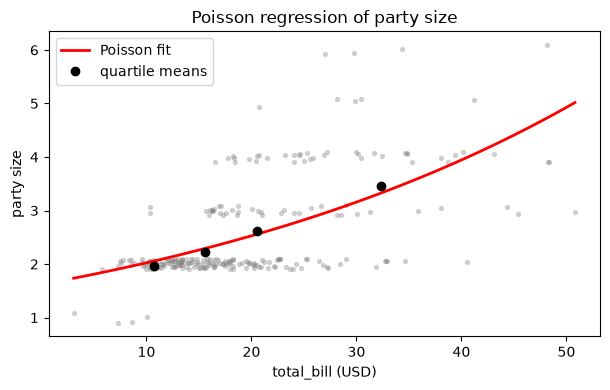

In [12]:
Xp = np.column_stack([np.ones(n), bill])
pois = sm.GLM(size_, Xp, family=sm.families.Poisson()).fit()
b1p, s1p = pois.params[1], pois.bse[1]
print(f'ln(mu) = {pois.params[0]:.4f} + {b1p:.5f} bill,   s{{b1}} = {s1p:.5f},  Wald z = {b1p/s1p:.2f}, P = {2*stats.norm.sf(abs(b1p/s1p)):.2e}')
print(f'rate ratio per USD: {np.exp(b1p):.4f}; per 10 USD: {np.exp(10*b1p):.3f}  (95% CI {np.exp(10*(b1p-1.96*s1p)):.3f}, {np.exp(10*(b1p+1.96*s1p)):.3f})')
print(f'expected party size at bill 10 / 20 / 30 USD: {np.exp(pois.params[0] + b1p*10):.2f} / {np.exp(pois.params[0] + b1p*20):.2f} / {np.exp(pois.params[0] + b1p*30):.2f}')
G_p = -2 * (sm.GLM(size_, np.ones((n, 1)), family=sm.families.Poisson()).fit().llf - pois.llf)
print(f'likelihood ratio vs intercept only: G2 = {G_p:.2f} on 1 df, P = {stats.chi2.sf(G_p, 1):.2e}')

disp = pois.pearson_chi2 / pois.df_resid
print(f'\ndeviance = {pois.deviance:.1f} on {int(pois.df_resid)} df;   Pearson chi2 / df = {disp:.3f}   ({"overdispersed" if disp > 1.5 else "underdispersed" if disp < 0.67 else "close to 1"})')
print(f'observed variance / mean of size = {size_.var(ddof=1)/size_.mean():.3f}   (Poisson: 1)')
print(f'quasi-Poisson standard error of b1 = {s1p*np.sqrt(disp):.5f}  (Poisson {s1p:.5f}); the Poisson se is therefore conservative here')

qs = np.quantile(bill, [0, .25, .5, .75, 1.0]); qi = np.clip(np.digitize(bill, qs[1:-1]), 0, 3)
print(f'\n{"bill quartile":>18}{"mean bill":>11}{"observed mean size":>20}{"fitted":>9}{"var/mean":>10}')
for g in range(4):
    m_ = qi == g
    print(f'{f"{qs[g]:.1f}-{qs[g+1]:.1f}":>18}{bill[m_].mean():>11.1f}{size_[m_].mean():>20.3f}{pois.fittedvalues[m_].mean():>9.3f}{size_[m_].var(ddof=1)/size_[m_].mean():>10.3f}')

grid = np.linspace(bill.min(), bill.max(), 100)
plt.figure(figsize=(6.2, 4))
plt.scatter(bill, size_ + np.random.default_rng(0).uniform(-.1, .1, n), s=8, alpha=.3, color='gray')
plt.plot(grid, np.exp(pois.params[0] + b1p * grid), 'r-', lw=2, label='Poisson fit')
plt.plot([bill[qi == g].mean() for g in range(4)], [size_[qi == g].mean() for g in range(4)], 'ko', label='quartile means')
plt.xlabel('total_bill (USD)'); plt.ylabel('party size'); plt.legend(); plt.title('Poisson regression of party size')
plt.tight_layout()
plt.savefig('images/poisson_fit.png')
plt.show()

## The GLM view (slide 30)

| model | response | distribution | link $g(\mu)$ | fitted here |
|---|---|---|---|---|
| ordinary linear | continuous | normal | identity | weeks 1–7 (tip) |
| logistic | binary | binomial | logit $\ln\frac{\mu}{1-\mu}$ | smoker |
| Poisson | count | Poisson | log $\ln\mu$ | party size |

Only the distribution, the link and the estimation method (maximum likelihood instead of least squares) change; the linear predictor $\eta=\beta_0+\beta_1X_1+\dots$ and the workflow (fit, test, diagnose, predict) stay.

## Summary

- Smoking status is only weakly predictable. The model `bill + size + day` is significant ($G^2=37.6$, 5 df, $P=5\times10^{-7}$) but McFadden's $R^2=0.116$ is well below the $0.2$–$0.4$ range of a good fit;
  AUC $=0.72$ in sample, $0.69$ on held-out halves.
- Adjusted odds ratios: $0.554$ per extra person ($0.366$–$0.839$), $1.064$ per USD of bill, and Saturday/Sunday/Thursday against Friday $0.25/0.09/0.11$. Fridays are the main driver but only $19$ parties.
- AIC and SBC both pick `bill + size + day` among $32$ subsets; Hosmer–Lemeshow $P=0.72$. No case is influential (largest Cook-type distance $0.055$).
- At cutoff $0.5$ sensitivity is only $0.42$; the Youden cutoff $0.407$ gives sensitivity $0.63$, specificity $0.76$, accuracy $0.71$ (the rule "nobody smokes" gets $0.62$).
- `size == 6` (0 smokers of 4) makes the ML coefficient diverge: separation, a data problem.
- Probit and cloglog fit no better than logit (AIC $298.8$, $299.2$ vs $298.7$); logit/probit coefficient ratio $\approx1.67$.
- Party size is underdispersed for a Poisson ($\chi^2/df=0.21$) and zero-truncated; rate ratio $1.249$ per $10$ USD of bill.
